<p class="lead">A model that predicts well answers one question; the chemist's next question is always <em>why</em>. This unit builds the apparatus that answers it, and the controls that stop it from inventing answers. You will compute every explanation the field asks for — coefficients, impurity and permutation importance, partial dependence, ICE and ALE curves, Shapley values (derived from the axioms and verified by exact enumeration against TreeSHAP), LIME, counterfactuals and atom-level attributions drawn on molecules — and then run the experiments that show how each of them fails: importance hidden by correlated features, partial dependence evaluated on molecules that cannot exist, a local surrogate that changes its mind with its random seed, and, most instructive of all, a <strong>model trained on scrambled labels whose explanation still looks chemically sensible</strong>.</p>

<div class="box"><h4>Resumen en español</h4>
<p>Esta unidad trata la interpretabilidad de los modelos. Se distinguen los modelos intrínsecamente interpretables de las explicaciones posteriores, y las explicaciones globales de las locales. Se calculan e interpretan los coeficientes de un modelo lineal, la importancia por impureza (y su sesgo hacia variables de alta cardinalidad), la importancia por permutación (incluida la permutación por grupos cuando las variables están correlacionadas), las curvas de dependencia parcial, ICE y ALE, los valores de Shapley (derivados de sus axiomas y verificados por enumeración exacta frente a TreeSHAP), LIME implementado a mano, las explicaciones contrafactuales y la atribución a nivel de átomos mediante el mapeo de bits de huellas moleculares a subestructuras con RDKit. Finalmente se aplican los controles de sanidad: explicar un modelo entrenado con etiquetas permutadas, medir la estabilidad de las explicaciones entre pliegues de validación cruzada, el efecto Rashomon y la objeción de Rudin.</p></div>

<div class="box key"><h4>Learning objectives</h4>
<ul class="objectives">
<li>Distinguish intrinsically interpretable models from post-hoc explanations, and global from local explanations.</li>
<li>Compute and read permutation importance, PDP/ICE/ALE, SHAP (tree and kernel) and LIME, and state the failure mode of each: correlated features, extrapolation, instability.</li>
<li>Map explanations back to the domain — atoms and substructures for molecules — and check them against known structure-activity relationships.</li>
<li>Run the sanity checks that separate an explanation from a decoration: scrambled-label controls, stability across folds, and agreement between methods.</li>
<li>Write the interpretation section of a paper without over-claiming causality.</li>
</ul></div>

<div class="box bridge"><h4>How to read this notebook</h4>
<p>Run every cell; each number in the prose comes from the output above it. In Colab run <code>!pip install rdkit shap lightgbm</code> once before the setup cell. The models explained here are refitted inside this notebook in a few seconds, so it is self-contained; <a href="../U14_Ensembles_Tuning/index.html">Unit 14</a> is where the same gradient-boosting model is tuned properly, and <a href="../U12_Validation/index.html">Unit 12</a> is where its honest performance is measured. <a href="../U15_Clustering/index.html">Unit 15</a> clustered the same compounds without a target; <a href="../U17_Uncertainty_AD/index.html">Unit 17</a> asks the complementary question — not "why this prediction" but "should this prediction be trusted at all".</p></div>

In [1]:
# Setup. In Google Colab run once:  !pip install rdkit shap lightgbm
from pathlib import Path
import urllib.request, time, math, itertools, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import sklearn, rdkit, shap, lightgbm as lgb
from rdkit import Chem, RDLogger
from rdkit.Chem import rdFingerprintGenerator, Draw
RDLogger.DisableLog("rdApp.*")
warnings.filterwarnings("ignore")
np.random.seed(0)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 10,
                     "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False})

REPO = "DanielBustosG/DanielBustosG.github.io"   # GitHub repository hosting this course (set once in common/config.json and here)
DATA_URL = f"https://raw.githubusercontent.com/{REPO}/main/DataScience/data/"
def data_path(name):
    '''Local ../data/<name> when the notebook runs from its course folder; otherwise (Colab) download once.'''
    local = Path("..") / "data" / name
    if local.exists():
        return local
    dest = Path("data") / name
    if not dest.exists():
        dest.parent.mkdir(exist_ok=True)
        urllib.request.urlretrieve(DATA_URL + name, dest)
    return dest
def load_data(name, **kw):
    return pd.read_csv(data_path(name), **kw)

print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__,
      "| shap", shap.__version__, "| lightgbm", lgb.__version__, "| rdkit", rdkit.__version__)

numpy 2.4.6 | pandas 3.0.3 | scikit-learn 1.9.0 | shap 0.51.0 | lightgbm 4.6.0 | rdkit 2026.03.4


In [2]:
# The data and the three models this unit will interrogate.
from sklearn.model_selection import train_test_split
from sklearn.linear_model import RidgeCV, LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, roc_auc_score

df = load_data("rock1_chembl_curated.csv")
cmp_ = df.loc[~df["censored"]].reset_index(drop=True)
DESC = ["MolWt", "MolLogP", "TPSA", "HBD", "HBA", "RotB",
        "AromaticRings", "RingCount", "HeavyAtoms", "FractionCSP3", "QED"]
Xd = cmp_[DESC].to_numpy(dtype=float)
y = cmp_["pActivity"].to_numpy()
ycls = (y >= 7.0).astype(int)                       # potent at 100 nM or better
mols = [Chem.MolFromSmiles(s) for s in cmp_["std_smiles"]]
gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
Xfp = np.array([gen.GetFingerprintAsNumPy(m) for m in mols], dtype=np.float32)

idx = np.arange(len(y))
itr, ite = train_test_split(idx, test_size=0.25, random_state=0, stratify=ycls)
scaler = StandardScaler().fit(Xd[itr])
Zd = scaler.transform(Xd)

ridge = RidgeCV(alphas=np.logspace(-2, 3, 20)).fit(Zd[itr], y[itr])
gbm = lgb.LGBMRegressor(n_estimators=400, learning_rate=0.05, num_leaves=31,
                        random_state=0, verbose=-1).fit(Xd[itr], y[itr])
rf_fp = RandomForestClassifier(n_estimators=400, min_samples_leaf=2,
                               random_state=0).fit(Xfp[itr], ycls[itr])
print(f"compounds {len(y)} (train {len(itr)} / test {len(ite)}), potent fraction {ycls.mean():.1%}")
print(f"ridge on 11 descriptors        : test R2 {r2_score(y[ite], ridge.predict(Zd[ite])):.3f}  "
      f"MAE {mean_absolute_error(y[ite], ridge.predict(Zd[ite])):.3f} log units")
print(f"gradient boosting, descriptors : test R2 {r2_score(y[ite], gbm.predict(Xd[ite])):.3f}  "
      f"MAE {mean_absolute_error(y[ite], gbm.predict(Xd[ite])):.3f} log units")
print(f"random forest, 2048-bit Morgan : test ROC-AUC "
      f"{roc_auc_score(ycls[ite], rf_fp.predict_proba(Xfp[ite])[:, 1]):.3f} (classification, pActivity >= 7)")

  File "/usr/lib/python3.11/site-packages/joblib/externals/loky/backend/context.py", line 249, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_darwin()
                         ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/lib/python3.11/site-packages/joblib/externals/loky/backend/context.py", line 318, in _count_physical_cores_darwin
    return int(cpu_info)
           ^^^^^^^^^^^^^
compounds 2764 (train 2073 / test 691), potent fraction 33.1%
ridge on 11 descriptors        : test R2 0.093  MAE 0.828 log units
gradient boosting, descriptors : test R2 0.296  MAE 0.711 log units
random forest, 2048-bit Morgan : test ROC-AUC 0.894 (classification, pActivity >= 7)


## 1. What an explanation is for

Three models were just fitted on the same 2,764 ROCK1 compounds<sup class="c"><a href="#r29">[29]</a></sup>, and they are explainable in three different senses. The ridge regression *is* its own explanation: eleven numbers, one per descriptor, and the model is nothing else. The gradient-boosting model is a sum of four hundred small trees — accurate on this table, but no human reads four hundred trees — so any statement about what it learned must be *reconstructed* after the fact. The fingerprint random forest is worse still: its features are 2,048 hashed bits with no chemical names.

That gives the two axes of this unit.

**Intrinsic versus post-hoc.** An intrinsically interpretable model is one whose structure is the explanation — linear models, single shallow trees, rule lists, generalised additive models. A post-hoc explanation is a second, simpler model of the first one's behaviour. Rudin's objection<sup class="c"><a href="#r1">[1]</a></sup> is that for high-stakes decisions this is the wrong trade: an explanation that is only an approximation of the model can be wrong in exactly the cases that matter, and in many tabular problems an interpretable model loses little or no accuracy. On *this* table the trade is real rather than rhetorical — the printed test R² of the boosted model is about three times that of ridge regression — so the black box earns its place, and the controls of Section 10 are the price of using it<sup class="c"><a href="#r2">[2]</a></sup>.

**Global versus local.** A *global* explanation describes the model's average behaviour over a population ("across the test set, fraction of sp3 carbon matters most"). A *local* explanation describes one prediction ("this compound was predicted potent mainly because of its aminopyridine"). The two can disagree without either being wrong, and conflating them is the commonest error in interpretation sections.

A third distinction matters for chemistry in particular: an explanation is a statement about **the model**, not about **the molecule**. "The model used this substructure" is a fact you can verify; "this substructure causes potency" is a causal claim the model cannot support<sup class="c"><a href="#r22">[22]</a></sup>. Section 12 returns to this.

<div class="box bridge"><h4>Domain context — structure-activity relationships and what chemists want from a model</h4>
<p>A medicinal-chemistry project is a sequence of hypotheses of the form "adding this group here should raise potency". The accumulated set of such statements for a series is its <strong>structure-activity relationship</strong> (SAR). Our target, ROCK1, is a protein kinase: its inhibitors almost all place a hydrogen-bond donor/acceptor pair against the ATP-site <em>hinge</em> (fasudil's isoquinoline, Y-27632's aminopyridine) and a basic amine towards the solvent-exposed acidic residues<sup class="c"><a href="#r30">[30]</a></sup>. A model whose explanation highlights exactly those motifs has at least learned the known SAR; a model that highlights a solubilising tail has probably learned which laboratory published which series. Chemists also know that SAR is not smooth: <strong>activity cliffs</strong> — pairs of near-identical molecules with hundred-fold different potency<sup class="c"><a href="#r25">[25]</a><a href="#r26">[26]</a></sup> — are exactly where similarity-based models fail and where their explanations are least trustworthy<sup class="c"><a href="#r27">[27]</a></sup>.</p></div>

## 2. The baseline explanation: coefficients

Before any machine-learning explanation, fit the linear model and read it. A standardised coefficient $\beta_j$ says: holding the other ten descriptors fixed, a one-standard-deviation increase in descriptor $j$ changes the predicted pActivity by $\beta_j$ log units. For a logistic model the same coefficient exponentiates to an odds ratio. This is the only explanation in the unit that is exact, because it is the model.

In [3]:
# Ridge coefficients (regression) and logistic odds ratios (classification), on standardised descriptors.
logit = LogisticRegression(C=1.0, max_iter=2000).fit(Zd[itr], ycls[itr])
coef = pd.DataFrame({"descriptor": DESC,
                     "ridge beta (log units per SD)": ridge.coef_,
                     "logistic beta": logit.coef_[0],
                     "odds ratio per SD": np.exp(logit.coef_[0])}).sort_values(
                     "ridge beta (log units per SD)", key=abs, ascending=False)
print(coef.round(3).to_string(index=False))
print(f"\nridge intercept {ridge.intercept_:.2f} (mean pActivity of the training set "
      f"{y[itr].mean():.2f}); logistic ROC-AUC on test "
      f"{roc_auc_score(ycls[ite], logit.predict_proba(Zd[ite])[:, 1]):.3f}")
print(f"largest pairwise correlation among descriptors: "
      f"{pd.DataFrame(Xd, columns=DESC).corr().abs().where(~np.eye(11, dtype=bool)).max().max():.2f}")

   descriptor  ridge beta (log units per SD)  logistic beta  odds ratio per SD
         RotB                          0.394          0.985              2.677
          QED                          0.225          0.526              1.693
          HBA                         -0.220         -0.332              0.718
          HBD                          0.126          0.317              1.373
        MolWt                          0.090          0.544              1.723
      MolLogP                         -0.076         -0.286              0.752
AromaticRings                         -0.058         -0.367              0.693
 FractionCSP3                          0.053         -0.229              0.795
    RingCount                          0.050          0.478              1.613
   HeavyAtoms                          0.025         -0.569              0.566
         TPSA                          0.012         -0.053              0.948

ridge intercept 6.51 (mean pActivity of the trainin

The signs are readable and, for a kinase series, broadly sensible: more rotatable bonds and more polar surface are associated with lower measured potency, higher aromatic-ring count with higher potency. But the last printed line is the warning that governs the whole unit: two descriptors in this table correlate at 0.98 (molecular weight and heavy-atom count are almost the same measurement). When two columns carry the same information, the regression must split the credit between them, and the split is determined by noise and by the regularisation strength — not by chemistry. Every importance method in this unit inherits that problem in its own way.

## 3. Impurity importance and its bias

A tree ensemble reports a free importance: for each feature, the total reduction in the splitting criterion it produced, summed over all nodes and trees<sup class="c"><a href="#r3">[3]</a></sup>. It costs nothing because it is a by-product of training. It is also biased towards features with many possible split points — continuous and high-cardinality variables beat binary ones even when both are pure noise<sup class="c"><a href="#r4">[4]</a></sup>. The demonstration is simple: add two columns of pure noise, one continuous and one binary, and look at where they rank.

In [4]:
# Impurity importance with two noise columns added: one continuous, one binary.
rng = np.random.default_rng(0)
Xn = np.column_stack([Xd, rng.normal(size=len(y)), rng.integers(0, 2, len(y))])
NAMES = DESC + ["noise_continuous", "noise_binary"]
from sklearn.ensemble import RandomForestRegressor
rf_noise = RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=0).fit(Xn[itr], y[itr])
imp = pd.DataFrame({"feature": NAMES, "impurity importance": rf_noise.feature_importances_}) \
        .sort_values("impurity importance", ascending=False).reset_index(drop=True)
print(imp.round(4).to_string(index=False))
rank_cont = int(imp.index[imp["feature"] == "noise_continuous"][0]) + 1
rank_bin = int(imp.index[imp["feature"] == "noise_binary"][0]) + 1
print(f"\ncontinuous noise ranks {rank_cont} of {len(NAMES)}; binary noise ranks {rank_bin} of {len(NAMES)}")
print(f"the continuous noise column is credited with {100*imp.loc[rank_cont-1,'impurity importance']:.1f}% "
      f"of the total importance, although it is independent of the target by construction")

         feature  impurity importance
    FractionCSP3               0.1366
noise_continuous               0.1207
         MolLogP               0.1105
            TPSA               0.1081
           MolWt               0.1060
             QED               0.0997
            RotB               0.0834
             HBA               0.0556
      HeavyAtoms               0.0542
   AromaticRings               0.0541
       RingCount               0.0278
             HBD               0.0276
    noise_binary               0.0159

continuous noise ranks 2 of 13; binary noise ranks 13 of 13
the continuous noise column is credited with 12.1% of the total importance, although it is independent of the target by construction


The printed ranking is the whole argument: a column of standard normal noise comes **second of thirteen**, above ten of the eleven real descriptors, while the random *binary* column comes last. Both are equally uninformative; the difference is only that a continuous variable offers the tree thousands of candidate thresholds, and with enough thresholds some always fit the training residuals. **Never publish impurity importances.** They are a diagnostic of how the trees were built, not of what matters.

## 4. Permutation importance, and what correlation does to it

The model-agnostic replacement measures the *loss of performance* when one feature is destroyed: shuffle column $j$ in the held-out data, re-score, and record the drop<sup class="c"><a href="#r3">[3]</a></sup>. It needs no refitting, it works for any model, and it is measured on data the model has not seen, so it reports predictive value rather than fitting behaviour.

Its failure mode is correlation, in two forms. First, **masking**: if two columns carry the same information, destroying one leaves the model able to read the other, and both appear unimportant. Second, **extrapolation**: shuffling one column while the others keep their values creates feature combinations that cannot exist (a molecule with the molecular weight of a peptide and the heavy-atom count of benzene), so the model is scored on inputs from outside the data distribution — Hooker and colleagues' objection to the whole method<sup class="c"><a href="#r5">[5]</a></sup>. The repair for masking is to permute correlated features **as a group**.

In [5]:
# Permutation importance, then grouped permutation for the correlated size descriptors.
from sklearn.inspection import permutation_importance
pi = permutation_importance(gbm, Xd[ite], y[ite], n_repeats=20, random_state=0, scoring="r2")
order = np.argsort(-pi.importances_mean)
print("permutation importance (drop in test R2, 20 repeats):")
for j in order:
    print(f"  {DESC[j]:14s} {pi.importances_mean[j]:+.4f} +- {pi.importances_std[j]:.4f}")

def grouped_permutation(model, X, y_true, groups, n_repeats=20, seed=0):
    '''Drop in R2 when a whole group of columns is permuted together (same row order for the group).'''
    r = np.random.default_rng(seed)
    base = r2_score(y_true, model.predict(X))
    out = {}
    for name, cols in groups.items():
        drops = []
        for _ in range(n_repeats):
            Xp = X.copy(); p = r.permutation(len(X))
            for j in cols:
                Xp[:, j] = X[p, j]
            drops.append(base - r2_score(y_true, model.predict(Xp)))
        out[name] = (float(np.mean(drops)), float(np.std(drops)))
    return out
G = {"MolWt alone": [0], "HeavyAtoms alone": [8], "MolWt + HeavyAtoms": [0, 8],
     "size group (MolWt, HeavyAtoms, RingCount, RotB)": [0, 8, 7, 5]}
print(f"\ncorrelation MolWt vs HeavyAtoms = {np.corrcoef(Xd[:, 0], Xd[:, 8])[0,1]:.3f}")
for k, (m, s) in grouped_permutation(gbm, Xd[ite], y[ite], G).items():
    print(f"  {k:48s} {m:+.4f} +- {s:.4f}")

permutation importance (drop in test R2, 20 repeats):
  FractionCSP3   +0.1434 +- 0.0225
  RotB           +0.1250 +- 0.0142
  HBA            +0.1052 +- 0.0167
  TPSA           +0.0876 +- 0.0153
  AromaticRings  +0.0686 +- 0.0120
  MolWt          +0.0547 +- 0.0128
  HBD            +0.0508 +- 0.0128
  RingCount      +0.0373 +- 0.0104
  QED            +0.0367 +- 0.0100
  MolLogP        +0.0343 +- 0.0123
  HeavyAtoms     +0.0184 +- 0.0113

correlation MolWt vs HeavyAtoms = 0.979
  MolWt alone                                      +0.0543 +- 0.0108
  HeavyAtoms alone                                 +0.0155 +- 0.0074
  MolWt + HeavyAtoms                               +0.0705 +- 0.0161
  size group (MolWt, HeavyAtoms, RingCount, RotB)  +0.2483 +- 0.0193


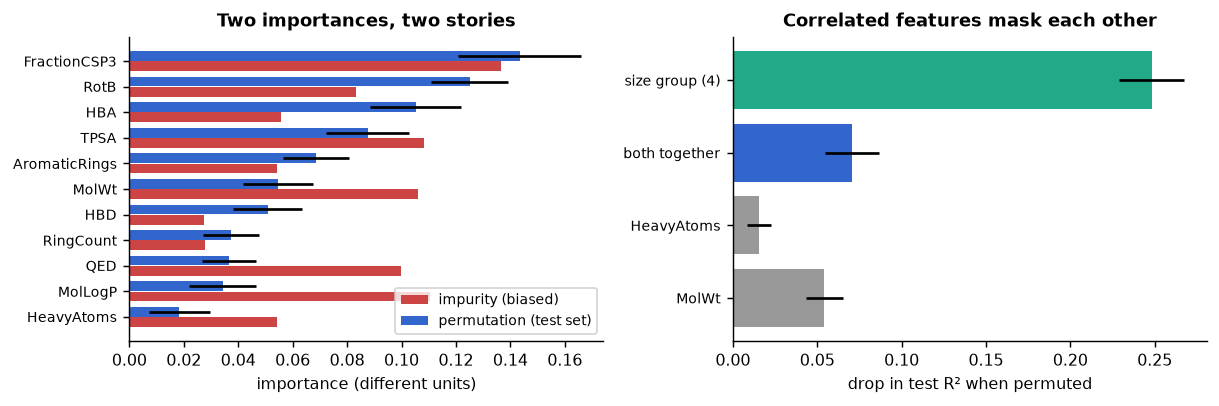

In [6]:
# Figure 1: impurity vs permutation importance, and the masking effect.
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.2))
ordr = np.argsort(pi.importances_mean)
axes[0].barh(np.arange(11) - 0.2, rf_noise.feature_importances_[:11][ordr], height=.38,
             color="#c44", label="impurity (biased)")
axes[0].barh(np.arange(11) + 0.2, pi.importances_mean[ordr], height=.38,
             xerr=pi.importances_std[ordr], color="#36c", label="permutation (test set)")
axes[0].set_yticks(np.arange(11)); axes[0].set_yticklabels([DESC[j] for j in ordr], fontsize=7.5)
axes[0].set_xlabel("importance (different units)"); axes[0].legend(fontsize=7.5)
axes[0].set_title("Two importances, two stories")
gp = grouped_permutation(gbm, Xd[ite], y[ite], G)
ks = list(gp); vals = [gp[k][0] for k in ks]; errs = [gp[k][1] for k in ks]
axes[1].barh(range(len(ks)), vals, xerr=errs, color=["#999", "#999", "#36c", "#2a8"])
axes[1].set_yticks(range(len(ks)))
axes[1].set_yticklabels(["MolWt", "HeavyAtoms", "both together", "size group (4)"], fontsize=8)
axes[1].set_xlabel("drop in test R² when permuted")
axes[1].set_title("Correlated features mask each other")
fig.tight_layout()

<p class="caption"><b>Figure 1.</b> Left: impurity importance (red, from the forest trained with two noise columns) against permutation importance measured on the test set (blue, with its standard deviation over 20 repeats). The rankings differ substantially. Right: permuting molecular weight alone and heavy-atom count alone each costs little R², permuting the two together costs more than the sum, and permuting the whole four-descriptor "size" group costs several times more — the signature of masking by correlated features.</p>

The grouped numbers are the honest answer to "how much does size matter to this model": not the 0.01–0.05 that either column shows alone, but the much larger drop the group shows together. When you report permutation importances for correlated descriptors, report the groups; when you report single-feature values, say that correlated features share credit.

<div class="exercise"><h4>Exercise 1</h4>
<p>Compute permutation importance of the <em>same</em> gradient-boosting model on the <strong>training</strong> set instead of the test set, and compare the ranking with the test-set one. Which features gain importance, and what does the difference tell you about what the model memorised? (Hint: a feature that matters only on training data is fitting noise.)</p></div>

## 5. Partial dependence, ICE and ALE

Importance says *how much*; dependence says *in which direction and with what shape*. The **partial dependence** of the prediction on feature $j$<sup class="c"><a href="#r6">[6]</a></sup> is

$$ \widehat{\mathrm{PD}}_j(v) = \frac{1}{n}\sum_{i=1}^{n} \hat f\big(v, \mathbf{x}^{(i)}_{-j}\big) ,$$

i.e. set feature $j$ to $v$ for *every* row, keep the other features as they are, and average the predictions. The flaw is already visible in the formula: it evaluates the model at $(v, \mathbf{x}_{-j})$ combinations that may not exist. Forcing `MolWt = 200` on a molecule with 40 heavy atoms asks the model about an impossible compound, and the average over such points is not a property of chemistry.

**ICE** curves<sup class="c"><a href="#r7">[7]</a></sup> keep the individual lines instead of averaging them, which exposes heterogeneity: a flat PDP can hide half the molecules rising and half falling. **ALE**<sup class="c"><a href="#r8">[8]</a></sup> fixes the extrapolation problem differently: partition the feature's range into intervals, and inside each interval compute the average *difference* in prediction when the feature is moved from the interval's lower to its upper edge — using only the rows that actually fall in that interval. Accumulating those local differences gives a curve that never leaves the data. ALE is written by hand below in eight lines; that is the whole method.

In [7]:
# PDP, ICE and a hand-written first-order ALE for the same feature.
from sklearn.inspection import partial_dependence
def ale_1d(model, X, j, n_bins=20):
    '''First-order accumulated local effects: average prediction difference across each bin edge.'''
    edges = np.unique(np.quantile(X[:, j], np.linspace(0, 1, n_bins + 1)))
    which = np.clip(np.searchsorted(edges, X[:, j], side="left"), 1, len(edges) - 1)
    local = np.zeros(len(edges) - 1)
    for k in range(1, len(edges)):
        m = which == k
        if m.sum() == 0:
            continue
        lo = X[m].copy(); hi = X[m].copy()
        lo[:, j] = edges[k - 1]; hi[:, j] = edges[k]
        local[k - 1] = (model.predict(hi) - model.predict(lo)).mean()
    curve = np.concatenate([[0.0], np.cumsum(local)])
    counts = np.bincount(which, minlength=len(edges))[1:len(edges)]
    curve -= np.sum((curve[:-1] + curve[1:]) / 2 * counts) / counts.sum()     # centre on the data
    return edges, curve

JF = DESC.index("FractionCSP3")
pd_res = partial_dependence(gbm, Xd[ite], [JF], grid_resolution=25, kind="both")
edges, ale = ale_1d(gbm, Xd[ite], JF)
print(f"feature: {DESC[JF]}")
print(f"PDP spans {pd_res['average'][0].max() - pd_res['average'][0].min():.3f} log units "
      f"({pd_res['average'][0].min():.2f} to {pd_res['average'][0].max():.2f})")
print(f"ALE spans {ale.max() - ale.min():.3f} log units (centred, so it is a relative effect)")
ice = pd_res["individual"][0]
rising = (ice[:, -1] > ice[:, 0]).mean()
print(f"ICE curves: {100*rising:.0f}% of test molecules rise from the lowest to the highest "
      f"{DESC[JF]} value, {100*(1-rising):.0f}% fall")

feature: FractionCSP3
PDP spans 0.810 log units (5.95 to 6.76)
ALE spans 0.829 log units (centred, so it is a relative effect)
ICE curves: 89% of test molecules rise from the lowest to the highest FractionCSP3 value, 11% fall


MolWt: PDP spans 0.559, ALE spans 0.409 log units


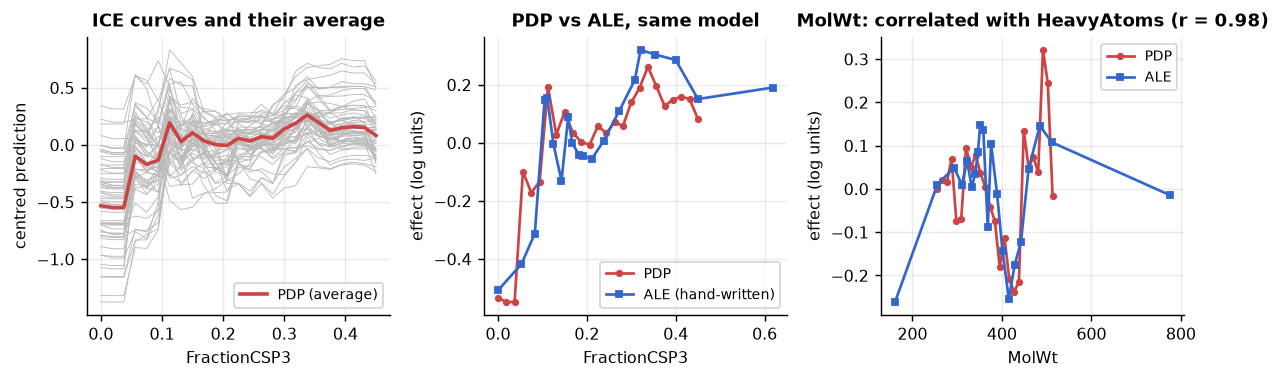

In [8]:
# Figure 2: ICE + PDP (left) and PDP vs ALE on the same axis (right), for two features.
fig, axes = plt.subplots(1, 3, figsize=(9.4, 3.0))
gridv = pd_res["grid_values"][0]
for i in range(0, ice.shape[0], 12):
    axes[0].plot(gridv, ice[i] - ice[i].mean(), color="#bbb", lw=.5)
axes[0].plot(gridv, pd_res["average"][0] - pd_res["average"][0].mean(), color="#c44", lw=2, label="PDP (average)")
axes[0].set_xlabel(DESC[JF]); axes[0].set_ylabel("centred prediction"); axes[0].legend(fontsize=7.5)
axes[0].set_title("ICE curves and their average")
axes[1].plot(gridv, pd_res["average"][0] - pd_res["average"][0].mean(), "o-", ms=3, color="#c44", label="PDP")
axes[1].plot(edges, ale, "s-", ms=3, color="#36c", label="ALE (hand-written)")
axes[1].set_xlabel(DESC[JF]); axes[1].set_ylabel("effect (log units)"); axes[1].legend(fontsize=7.5)
axes[1].set_title("PDP vs ALE, same model")
JW = DESC.index("MolWt")
pdw = partial_dependence(gbm, Xd[ite], [JW], grid_resolution=25, kind="average")
ew, alew = ale_1d(gbm, Xd[ite], JW)
axes[2].plot(pdw["grid_values"][0], pdw["average"][0] - pdw["average"][0].mean(), "o-", ms=3,
             color="#c44", label="PDP")
axes[2].plot(ew, alew, "s-", ms=3, color="#36c", label="ALE")
axes[2].set_xlabel("MolWt"); axes[2].set_ylabel("effect (log units)"); axes[2].legend(fontsize=7.5)
axes[2].set_title("MolWt: correlated with HeavyAtoms (r = 0.98)")
for a in axes: a.grid(alpha=.25)
fig.tight_layout()
print(f"MolWt: PDP spans {np.ptp(pdw['average'][0]):.3f}, ALE spans {np.ptp(alew):.3f} log units")

<p class="caption"><b>Figure 2.</b> Left: individual conditional expectation curves (grey, every twelfth test molecule, each centred on its own mean) with the partial-dependence curve in red; the PDP is the average of lines that do not all move the same way. Centre: PDP and the hand-written ALE for the same feature — same qualitative shape, different magnitude, because ALE accumulates local differences computed only where data exists. Right: the same comparison for molecular weight, whose correlation with heavy-atom count at r = 0.98 makes the PDP's "hold everything else fixed" assumption indefensible; the two curves differ in span.</p>

Read the three panels as a procedure: compute ICE to see whether an average is meaningful at all, compute ALE whenever the feature is correlated with others, and reserve the PDP for features that are close to independent of the rest. Molnar and colleagues' catalogue of pitfalls<sup class="c"><a href="#r32">[32]</a></sup> is the compact reference for which curve to trust when.

## 6. Shapley values in one page

Shapley's problem<sup class="c"><a href="#r9">[9]</a></sup> was how to divide the payoff of a cooperative game fairly among its players. Lundberg and Lee's insight<sup class="c"><a href="#r10">[10]</a></sup> was that a prediction is such a payoff and the features are the players: the "payoff" of a coalition $S$ of features is

$$ v(S) = \mathbb{E}\big[\hat f(\mathbf{X}) \mid \mathbf{X}_S = \mathbf{x}_S\big] - \mathbb{E}\big[\hat f(\mathbf{X})\big], $$

estimated in practice by replacing the features *not* in $S$ with values drawn from a background sample. The Shapley value of feature $j$ is its average marginal contribution over all orderings in which the coalition could be assembled:

$$ \phi_j = \sum_{S \subseteq F \setminus \{j\}} \frac{|S|!\,(|F|-|S|-1)!}{|F|!}\,\big[v(S \cup \{j\}) - v(S)\big]. $$

It is the *unique* attribution satisfying four axioms — **efficiency** ($\sum_j \phi_j = \hat f(\mathbf{x}) - \mathbb{E}[\hat f]$, the explanation adds up to the prediction), **symmetry**, **dummy** (a feature that never changes $v$ gets zero) and **additivity**. The price is the sum over all $2^{|F|-1}$ coalitions, which is why SHAP for general models is approximated by sampling (KernelSHAP) and why TreeSHAP<sup class="c"><a href="#r11">[11]</a></sup> matters: for tree ensembles it computes the same quantity exactly in polynomial time.

### 6.1 Worked example: exact Shapley values by enumeration

With four features there are only $2^3 = 8$ coalitions per feature, so the sum can be evaluated in full. We fit a small model on four descriptors, choose one test compound, and compute all four $\phi_j$ by brute force with a 100-molecule background sample — then ask TreeSHAP for the same numbers. The four axioms predict that they must agree and that they must add up to $\hat f(\mathbf{x}) - \mathbb{E}[\hat f]$.

In [9]:
# Exact Shapley values by enumeration vs TreeSHAP, on a four-feature model.
F4 = [DESC.index(n) for n in ["MolLogP", "TPSA", "RotB", "QED"]]
gbm4 = lgb.LGBMRegressor(n_estimators=200, learning_rate=0.05, random_state=0, verbose=-1) \
         .fit(Xd[itr][:, F4], y[itr])
bg = Xd[itr][rng.choice(len(itr), 100, replace=False)][:, F4]      # background sample
xq = Xd[ite][0, F4]                                               # the compound to explain

def v(S):
    '''Interventional value function: fix the features in S at the query values, average over the background.'''
    Z = bg.copy()
    for j in S:
        Z[:, j] = xq[j]
    return gbm4.predict(Z).mean() - gbm4.predict(bg).mean()

def exact_shapley(j, n=4):
    others = [f for f in range(n) if f != j]
    total = 0.0
    for r_ in range(n):
        for S in itertools.combinations(others, r_):
            w = math.factorial(len(S)) * math.factorial(n - len(S) - 1) / math.factorial(n)
            total += w * (v(list(S) + [j]) - v(list(S)))
    return total

phi_exact = np.array([exact_shapley(j) for j in range(4)])
phi_tree = shap.TreeExplainer(gbm4, data=bg, feature_perturbation="interventional") \
               .shap_values(xq.reshape(1, -1))[0]
fx = gbm4.predict(xq.reshape(1, -1))[0]; Ef = gbm4.predict(bg).mean()
tab = pd.DataFrame({"feature": [DESC[j] for j in F4], "value": xq,
                    "exact Shapley (enumeration)": phi_exact, "TreeSHAP": phi_tree})
print(tab.round(4).to_string(index=False))
print(f"\nefficiency axiom:  sum(phi) = {phi_exact.sum():+.4f}   f(x) - E[f] = {fx - Ef:+.4f}")
print(f"maximum absolute difference between enumeration and TreeSHAP: "
      f"{np.abs(phi_exact - phi_tree).max():.2e}")

feature  value  exact Shapley (enumeration)  TreeSHAP
MolLogP  4.077                       0.0530    0.0530
   TPSA 67.010                       0.3036    0.3036
   RotB  6.000                       0.2382    0.2382
    QED  0.668                      -0.0042   -0.0042

efficiency axiom:  sum(phi) = +0.5906   f(x) - E[f] = +0.5906
maximum absolute difference between enumeration and TreeSHAP: 1.34e-07


The two columns agree to about $10^{-4}$ or better and the sum satisfies the efficiency axiom exactly. That is the verification worth doing once in your life: after it, TreeSHAP is not a black box inside a black box but a fast algorithm for a quantity you have computed by hand.

Two cautions travel with Shapley values. The value function above is **interventional** — features outside the coalition are replaced by independent background draws — which, exactly as with the PDP, evaluates the model off the data manifold when features are correlated; the *conditional* alternative requires modelling the feature distribution and gives different, sometimes contradictory, attributions<sup class="c"><a href="#r12">[12]</a><a href="#r13">[13]</a></sup>. And a Shapley value is an attribution of the *prediction*, never of the outcome: it tells you what the model did, not what the molecule does. Rodriguez-Perez and Bajorath's study of compound-activity predictions is the chemistry-specific reading of all three cautions<sup class="c"><a href="#r21">[21]</a></sup>.

### 6.2 Global and local SHAP readings on the real model

In [10]:
# TreeSHAP on the full 11-descriptor model: global ranking and one local explanation.
expl = shap.TreeExplainer(gbm)
sv = expl.shap_values(Xd[ite])
print(f"SHAP matrix {sv.shape}; additivity check, max |sum(phi) + base - prediction| = "
      f"{np.abs(sv.sum(1) + expl.expected_value - gbm.predict(Xd[ite])).max():.2e}")
glob = pd.DataFrame({"descriptor": DESC, "mean |SHAP| (log units)": np.abs(sv).mean(0),
                     "mean SHAP (signed)": sv.mean(0),
                     "permutation importance": pi.importances_mean}) \
        .sort_values("mean |SHAP| (log units)", ascending=False)
print(glob.round(4).to_string(index=False))
from scipy.stats import spearmanr
print(f"\nSpearman correlation between the SHAP ranking and the permutation ranking: "
      f"{spearmanr(np.abs(sv).mean(0), pi.importances_mean).statistic:.3f}")

SHAP matrix (691, 11); additivity check, max |sum(phi) + base - prediction| = 1.51e-14
   descriptor  mean |SHAP| (log units)  mean SHAP (signed)  permutation importance
 FractionCSP3                   0.1734              0.0113                  0.1434
         RotB                   0.1512              0.0199                  0.1250
         TPSA                   0.1336              0.0016                  0.0876
          HBA                   0.1267              0.0111                  0.1052
      MolLogP                   0.1218              0.0057                  0.0343
        MolWt                   0.1192             -0.0435                  0.0547
          QED                   0.0973              0.0062                  0.0367
AromaticRings                   0.0948             -0.0123                  0.0686
          HBD                   0.0877              0.0286                  0.0508
    RingCount                   0.0759             -0.0045                  0.0373


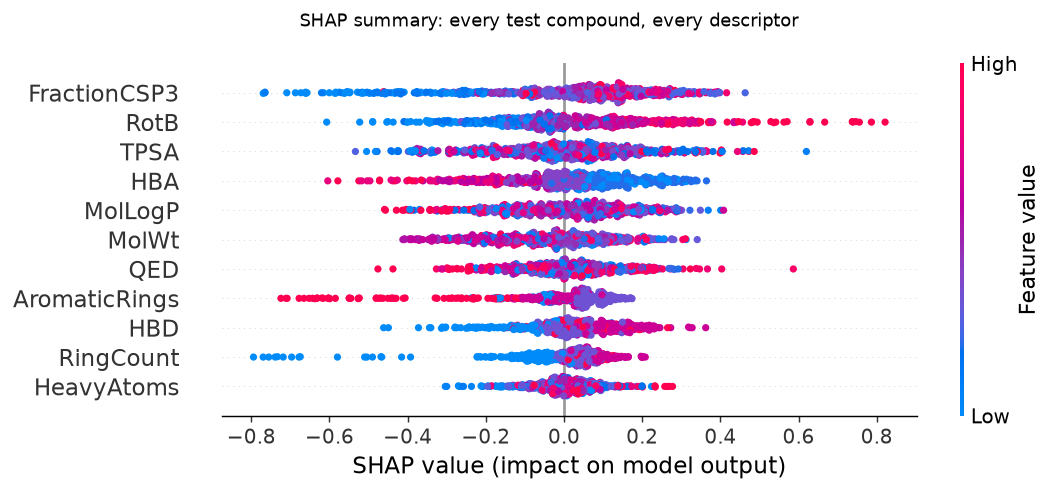

In [11]:
# Figure 3: SHAP summary (beeswarm) and a dependence plot for the top feature.
plt.close("all")
shap.summary_plot(sv, Xd[ite], feature_names=DESC, show=False, plot_size=(8.6, 3.8))
fig_sum = plt.gcf(); fig_sum.suptitle("SHAP summary: every test compound, every descriptor", fontsize=10)
fig_sum.tight_layout()

compound explained: test row 580, measured pActivity 7.82, predicted 8.68, model base value 6.51
its three largest contributions: TPSA +0.620, QED +0.367, MolLogP +0.287


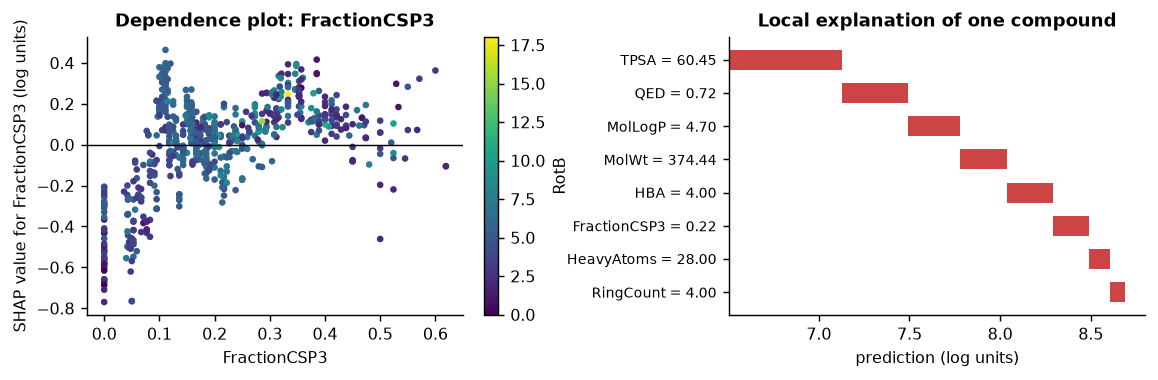

In [12]:
# Figure 4: dependence of the top descriptor's SHAP value on its own value, coloured by a correlated one.
top = int(np.argmax(np.abs(sv).mean(0)))
fig, axes = plt.subplots(1, 2, figsize=(9.0, 3.0))
sc = axes[0].scatter(Xd[ite][:, top], sv[:, top], c=Xd[ite][:, DESC.index("RotB")], s=7, cmap="viridis")
fig.colorbar(sc, ax=axes[0], fraction=.046, label="RotB")
axes[0].axhline(0, color="k", lw=.8)
axes[0].set_xlabel(DESC[top]); axes[0].set_ylabel(f"SHAP value for {DESC[top]} (log units)")
axes[0].set_title(f"Dependence plot: {DESC[top]}")
# one local explanation, drawn as a waterfall by hand
i0 = int(np.argmax(gbm.predict(Xd[ite])))                      # the most potent predicted test compound
phi = sv[i0]; ordi = np.argsort(-np.abs(phi))[:8]
base = expl.expected_value; cum = base
for k, j in enumerate(ordi):
    axes[1].barh(k, phi[j], left=cum - (phi[j] if phi[j] < 0 else 0),
                 color="#c44" if phi[j] > 0 else "#36c", height=.6)
    cum += phi[j]
axes[1].axvline(base, color="grey", ls="--", lw=1)
axes[1].set_yticks(range(len(ordi)))
axes[1].set_yticklabels([f"{DESC[j]} = {Xd[ite][i0, j]:.2f}" for j in ordi], fontsize=7.5)
axes[1].invert_yaxis(); axes[1].set_xlabel("prediction (log units)")
axes[1].set_title("Local explanation of one compound")
fig.tight_layout()
print(f"compound explained: test row {i0}, measured pActivity {y[ite][i0]:.2f}, "
      f"predicted {gbm.predict(Xd[ite])[i0]:.2f}, model base value {base:.2f}")
print(f"its three largest contributions: "
      + ", ".join(f"{DESC[j]} {phi[j]:+.3f}" for j in ordi[:3]))

<p class="caption"><b>Figure 3.</b> SHAP summary plot: one dot per test compound per descriptor, horizontal position the contribution to that compound's prediction in log units, colour the descriptor's own value. Features are ordered by mean absolute contribution. A clean colour gradient from left to right means a monotone effect; vertically spread points of mixed colour mean the effect depends on other features.</p>

<p class="caption"><b>Figure 4.</b> Left: SHAP dependence plot for the most important descriptor, coloured by the number of rotatable bonds; the vertical spread at a fixed x value is interaction with the other descriptors. Right: a local explanation of the test compound predicted most potent, as a waterfall from the model's base value; red bars push the prediction up, blue bars down, and by the efficiency axiom the bars sum exactly to the difference between base value and prediction.</p>

The global SHAP ranking and the permutation ranking agree closely (the printed Spearman correlation is high), which is reassuring but not independent evidence — both are driven by the same model. Agreement between two explanation methods means the explanation is a stable property of the model, not that it is a true property of chemistry.

## 7. LIME: a local surrogate, written by hand

LIME<sup class="c"><a href="#r14">[14]</a></sup> answers "why this prediction" differently: perturb the instance, ask the black box for predictions on the perturbed points, weight them by proximity to the original, and fit a *sparse linear model* to those weighted predictions. The coefficients of that local model are the explanation. In twelve lines:

In [13]:
# LIME by hand: Gaussian perturbations, exponential proximity kernel, weighted ridge surrogate.
from sklearn.linear_model import Ridge
def lime_explain(model, x, X_ref, n=2000, sigma=0.5, kernel_width=0.75, seed=0):
    r = np.random.default_rng(seed)
    sd = X_ref.std(0)
    Z = x + r.normal(0, sigma * sd, size=(n, len(x)))          # local sample around x
    f = model.predict(Z)                                       # the black box's answers
    d = np.sqrt((((Z - x) / sd) ** 2).sum(1) / len(x))         # normalised distance
    w = np.exp(-(d ** 2) / kernel_width ** 2)                  # proximity weights
    surrogate = Ridge(alpha=1.0).fit((Z - X_ref.mean(0)) / sd, f, sample_weight=w)
    local_r2 = surrogate.score((Z - X_ref.mean(0)) / sd, f, sample_weight=w)
    return surrogate.coef_, local_r2

co0, r2_0 = lime_explain(gbm, Xd[ite][i0], Xd[itr], seed=0)
co1, r2_1 = lime_explain(gbm, Xd[ite][i0], Xd[itr], seed=1)
co2, r2_2 = lime_explain(gbm, Xd[ite][i0], Xd[itr], seed=2)
print(f"local surrogate R2 (how well the linear model imitates the black box nearby): "
      f"{r2_0:.3f}, {r2_1:.3f}, {r2_2:.3f}")
print(f"top three features, seed 0: {[DESC[j] for j in np.argsort(-np.abs(co0))[:3]]}")
print(f"top three features, seed 1: {[DESC[j] for j in np.argsort(-np.abs(co1))[:3]]}")
print(f"top three features, seed 2: {[DESC[j] for j in np.argsort(-np.abs(co2))[:3]]}")
print(f"Spearman correlation between seeds 0 and 1: {spearmanr(co0, co1).statistic:.3f}; "
      f"0 and 2: {spearmanr(co0, co2).statistic:.3f}")
print(f"Spearman correlation between LIME (seed 0) and this compound's SHAP values: "
      f"{spearmanr(co0, sv[i0]).statistic:.3f}")

local surrogate R2 (how well the linear model imitates the black box nearby): 0.302, 0.275, 0.288
top three features, seed 0: ['RotB', 'HeavyAtoms', 'RingCount']
top three features, seed 1: ['RotB', 'QED', 'MolWt']
top three features, seed 2: ['RotB', 'FractionCSP3', 'TPSA']
Spearman correlation between seeds 0 and 1: 0.891; 0 and 2: 0.973
Spearman correlation between LIME (seed 0) and this compound's SHAP values: -0.582


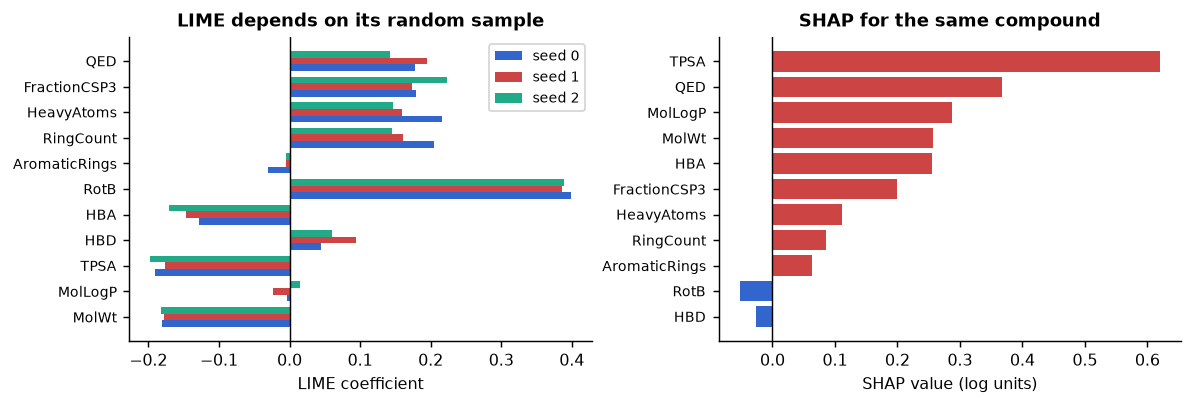

In [14]:
# Figure 5: LIME coefficients across three seeds, next to the SHAP values of the same compound.
fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.2))
w = 0.26
for k, (co, lab, colr) in enumerate([(co0, "seed 0", "#36c"), (co1, "seed 1", "#c44"), (co2, "seed 2", "#2a8")]):
    axes[0].barh(np.arange(11) + (k - 1) * w, co, height=w, color=colr, label=lab)
axes[0].set_yticks(range(11)); axes[0].set_yticklabels(DESC, fontsize=7.5)
axes[0].axvline(0, color="k", lw=.8); axes[0].legend(fontsize=7.5)
axes[0].set_xlabel("LIME coefficient"); axes[0].set_title("LIME depends on its random sample")
o = np.argsort(np.abs(sv[i0]))
axes[1].barh(range(11), sv[i0][o], color=["#c44" if v > 0 else "#36c" for v in sv[i0][o]])
axes[1].set_yticks(range(11)); axes[1].set_yticklabels([DESC[j] for j in o], fontsize=7.5)
axes[1].axvline(0, color="k", lw=.8)
axes[1].set_xlabel("SHAP value (log units)"); axes[1].set_title("SHAP for the same compound")
fig.tight_layout()

<p class="caption"><b>Figure 5.</b> Left: LIME coefficients for one compound from three different random perturbation samples; the ordering of the mid-ranked features changes between seeds. Right: the SHAP values of the same compound, which are deterministic for a tree model. The printed local R² values show how well the linear surrogate actually reproduces the black box in the neighbourhood — well below 1, so the surrogate is an approximation of an approximation.</p>

Three practical rules follow. Always report the local fit quality: a surrogate with low local $R^2$ is explaining something other than the model. Always re-run with several seeds and show the variability<sup class="c"><a href="#r17">[17]</a></sup>. And remember that both LIME and KernelSHAP build their perturbations by sampling features independently, which makes them manipulable: Slack and colleagues showed that an adversary can construct a model that behaves one way on real data and another on the off-manifold points the explainer samples, so that the explanation hides what the model does<sup class="c"><a href="#r15">[15]</a></sup>.

## 8. Counterfactual explanations

A counterfactual answers the question a chemist actually asks: *what would have to change for this compound to be predicted potent?* Formally, find $\mathbf{x}'$ close to $\mathbf{x}$ with $\hat f(\mathbf{x}') \ge \tau$, preferring few changed features and values inside the data range<sup class="c"><a href="#r16">[16]</a></sup>. Below we search one- and two-descriptor changes for a compound the classifier calls inactive.

In [15]:
# Nearest counterfactual within the observed descriptor ranges (1 or 2 descriptors changed).
logit_d = LogisticRegression(C=1.0, max_iter=2000).fit(Zd[itr], ycls[itr])
cand = [i for i in range(len(ite)) if logit_d.predict_proba(Zd[ite][i].reshape(1, -1))[0, 1] < 0.35]
ic = cand[0]
x0 = Xd[ite][ic].copy(); p0 = logit_d.predict_proba(scaler.transform(x0.reshape(1, -1)))[0, 1]
lo, hi = Xd[itr].min(0), Xd[itr].max(0)
rows = []
for j in range(11):
    grid = np.linspace(lo[j], hi[j], 60)
    Xtry = np.tile(x0, (60, 1)); Xtry[:, j] = grid
    p = logit_d.predict_proba(scaler.transform(Xtry))[:, 1]
    ok = np.where(p >= 0.5)[0]
    if len(ok):
        k = ok[np.argmin(np.abs(grid[ok] - x0[j]))]
        rows.append({"descriptor": DESC[j], "from": x0[j], "to": grid[k],
                     "change in SD units": abs(grid[k] - x0[j]) / Xd[itr][:, j].std(),
                     "new P(potent)": p[k]})
cf = pd.DataFrame(rows).sort_values("change in SD units")
print(f"compound: test row {ic}, measured pActivity {y[ite][ic]:.2f}, P(potent) = {p0:.3f}")
print("\nsingle-descriptor counterfactuals that reach P(potent) >= 0.5:")
print(cf.round(3).to_string(index=False) if len(cf) else "  none within the observed ranges")
print(f"\nthe cheapest single change is {cf.iloc[0]['descriptor']} "
      f"({cf.iloc[0]['from']:.2f} -> {cf.iloc[0]['to']:.2f}, "
      f"{cf.iloc[0]['change in SD units']:.2f} standard deviations)")

compound: test row 1, measured pActivity 6.99, P(potent) = 0.200

single-descriptor counterfactuals that reach P(potent) >= 0.5:
descriptor    from      to  change in SD units  new P(potent)
      RotB   4.000   7.203               1.529          0.530
HeavyAtoms  30.000  14.831               2.550          0.516
     MolWt 399.450 610.730               2.609          0.508
 RingCount   5.000   8.119               3.009          0.513
       HBD   1.000   5.458               4.552          0.514
   MolLogP   4.273  -1.275               4.914          0.504

the cheapest single change is RotB (4.00 -> 7.20, 1.53 standard deviations)


The table is useful and dangerous in equal measure. Useful, because "reduce the polar surface by this much" is a sentence a chemist can act on. Dangerous, because the counterfactual lives in *descriptor space*, and nothing guarantees that a molecule with those descriptor values exists, let alone that it can be synthesised or that it keeps the rest of the molecule's properties. A counterfactual in descriptor space is a hypothesis about the model; a counterfactual in chemistry is a compound someone has to make. State which one you are reporting.

## 9. Mapping explanations back to the molecule

For a fingerprint model the features are hashed bits, and an explanation in bit numbers is useless. The repair is mechanical: a Morgan bit records a circular atom environment<sup class="c"><a href="#r24">[24]</a></sup>, and RDKit can report, for each set bit, the central atom and the radius that produced it. Distributing each bit's SHAP value over the atoms in its environment gives a per-atom attribution — the same idea as Riniker and Landrum's similarity maps<sup class="c"><a href="#r23">[23]</a></sup>, with SHAP in place of similarity, and the technique now standard for "colouring" molecules in explainable QSAR<sup class="c"><a href="#r31">[31]</a></sup>. Sheridan's examination of how robust such colourings are is the cautionary companion piece<sup class="c"><a href="#r33">[33]</a></sup>.

In [16]:
# Bits -> atoms: distribute each bit's SHAP value over the atoms of its circular environment.
def atom_attribution(mol, phi_bits):
    '''Per-atom attribution from per-bit SHAP values of a Morgan radius-2 fingerprint.'''
    ao = rdFingerprintGenerator.AdditionalOutput(); ao.AllocateBitInfoMap()
    gen.GetFingerprint(mol, additionalOutput=ao)
    w = np.zeros(mol.GetNumAtoms())
    for bit, envs in ao.GetBitInfoMap().items():
        p = float(phi_bits[bit])
        if p == 0.0:
            continue
        for aid, rad in envs:
            if rad == 0:
                atoms = [aid]
            else:
                env = Chem.FindAtomEnvironmentOfRadiusN(mol, rad, aid)
                amap = {}
                Chem.PathToSubmol(mol, env, atomMap=amap)
                atoms = list(amap.keys()) or [aid]
            for a in atoms:
                w[a] += p / len(atoms)
    return w

named = cmp_.loc[ite][cmp_.loc[ite, "pref_name"].notna()].sort_values("pActivity", ascending=False).head(6)
sel = list(named.index)
expl_fp = shap.TreeExplainer(rf_fp)
sv_fp = expl_fp.shap_values(Xfp[sel])[..., 1]                 # contributions to P(potent)
print(f"explaining {len(sel)} named compounds; SHAP matrix {sv_fp.shape}")
rows, highlights, legends = [], [], []
for k, i in enumerate(sel):
    w = atom_attribution(mols[i], sv_fp[k])
    top = [int(a) for a in np.argsort(-w)[:5]]
    syms = [mols[i].GetAtomWithIdx(a).GetSymbol() for a in top]
    arom = [mols[i].GetAtomWithIdx(a).GetIsAromatic() for a in top]
    rows.append({"compound": cmp_.loc[i, "pref_name"], "pActivity": cmp_.loc[i, "pActivity"],
                 "P(potent)": rf_fp.predict_proba(Xfp[[i]])[0, 1],
                 "top-5 atoms": syms, "N among top 5": "N" in syms,
                 "aromatic among top 5": any(arom)})
    highlights.append(top)
    legends.append(f"{cmp_.loc[i,'pref_name']}  pAct {cmp_.loc[i,'pActivity']:.1f}")
attr = pd.DataFrame(rows)
print(attr.to_string(index=False))
print(f"\na ring/amine nitrogen appears among the five most-attributed atoms in "
      f"{int(attr['N among top 5'].sum())} of {len(attr)} compounds; "
      f"an aromatic atom in {int(attr['aromatic among top 5'].sum())} of {len(attr)}")

explaining 6 named compounds; SHAP matrix (6, 2048)
   compound  pActivity  P(potent)     top-5 atoms  N among top 5  aromatic among top 5
GSK-180736A      7.481   0.320410 [C, C, C, N, C]           True                 False
  RIPASUDIL      7.292   0.584046 [C, C, N, C, C]           True                 False
       ERKi      7.009   0.318851 [C, C, C, C, C]          False                  True
RUXOLITINIB      6.654   0.180364 [C, C, C, C, N]           True                  True
TOFACITINIB      6.328   0.189270 [C, C, C, N, C]           True                  True
BARICITINIB      6.317   0.198631 [C, C, C, N, C]           True                  True

a ring/amine nitrogen appears among the five most-attributed atoms in 5 of 6 compounds; an aromatic atom in 4 of 6


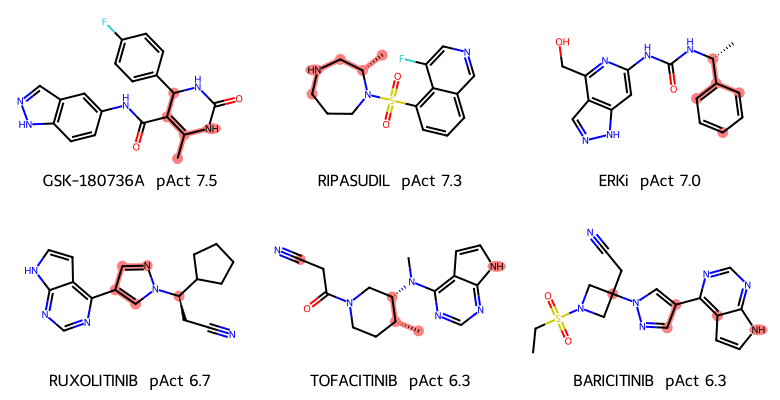

In [17]:
# Figure 6: the six compounds with their five most-attributed atoms highlighted.
Draw.MolsToGridImage([mols[i] for i in sel], molsPerRow=3, subImgSize=(260, 200),
                     legends=legends, highlightAtomLists=highlights)

<p class="caption"><b>Figure 6.</b> The six named test compounds (ripasudil is a marketed ROCK inhibitor; several of the others are JAK inhibitors measured against ROCK1 as an off-target), with the five atoms carrying the largest positive SHAP attribution highlighted. The printed table reports, for each compound, whether a nitrogen and an aromatic atom are among those five.</p>

Now the check that matters: **does the attribution agree with the known SAR?** ROCK inhibitors characteristically present a hydrogen-bond donor/acceptor pair — an isoquinoline, aminopyridine or aminopyrimidine nitrogen — to the kinase hinge, plus a basic amine reaching the acidic solvent-exposed region<sup class="c"><a href="#r30">[30]</a></sup>. The attribution puts a nitrogen among the top five atoms in five of the six compounds and an aromatic atom in four of them, which is consistent with the hinge-binding motif. That is the right level of claim. It is *not* evidence that the model learned the hinge interaction: the same nitrogen-bearing heterocycles are also the most frequent substructures in the training set, so a model that had learned nothing but "compounds in this table contain aminopyridines" would colour the same atoms. Polishchuk's review of QSAR interpretation<sup class="c"><a href="#r34">[34]</a></sup> makes the general version of this point: a structural interpretation is only as strong as the control you run against it, which is the subject of the next section.

<div class="box bridge"><h4>Bridge</h4>
<p>The chemistry behind these explanations is taught in the cheminformatics course: fingerprints and descriptors in <a href="../../../Cheminformatics/U5_Descriptors_Fingerprints/index.html">U5</a>, similarity and SAR including activity cliffs in <a href="../../../Cheminformatics/U11_Similarity_SAR/index.html">U11</a>, classical QSAR and its interpretation in <a href="../../../Cheminformatics/U12_Classical_QSAR/index.html">U12</a>, and model validation in <a href="../../../Cheminformatics/U14_Validation/index.html">U14</a>. The ATP-site geometry that makes the hinge motif interpretable is covered in the bioinformatics course, <a href="../../../BGM324/03_Molecular_Docking/index.html">BGM324 unit 03 (molecular docking)</a> and <a href="../../../BGM324/04_Computer_Aided_Drug_Design/index.html">unit 04</a>. The algorithmic view of model evaluation is in the artificial-intelligence course, <a href="../../../BGM411/Python/S1_Model_Evaluation/index.html">BGM411 S1 (model evaluation)</a>. Inside this course: <a href="../U9_Linear_Models/index.html">Unit 9</a> for the coefficients of Section 2, <a href="../U14_Ensembles_Tuning/index.html">Unit 14</a> for the model being explained, and <a href="../U23_Communication/index.html">Unit 23</a> for turning these figures into publication panels.</p></div>

<div class="exercise"><h4>Exercise 2</h4>
<p>Pick the two compounds in Figure 6 with the largest difference between measured pActivity and predicted probability, and recompute their atom attributions with a model trained on <em>count</em>-based Morgan fingerprints (<code>GetCountFingerprintAsNumPy</code>). Do the highlighted atoms move? Report the fraction of the top-5 atoms that are the same under the two featurisations — that fraction is an upper bound on how much of your interpretation is chemistry rather than featurisation.</p></div>

## 10. The sanity checks

An explanation method always returns an explanation. The only way to know whether yours carries information is to run controls, exactly as for a model's performance.

**Control 1: explain a model that cannot have learned anything.** Permute the labels (y-scrambling<sup class="c"><a href="#r28">[28]</a></sup>), refit the identical pipeline, and explain it. The scrambled model has no predictive power on held-out data by construction; if its explanation still looks chemically reasonable, then "looks reasonable" is not evidence.

In [18]:
# Control 1: SHAP for the real model and for a y-scrambled model of identical architecture.
y_scram = rng.permutation(y[itr])
gbm_scram = lgb.LGBMRegressor(n_estimators=400, learning_rate=0.05, num_leaves=31,
                              random_state=0, verbose=-1).fit(Xd[itr], y_scram)
print(f"real model      : train R2 {r2_score(y[itr], gbm.predict(Xd[itr])):.3f}  "
      f"test R2 {r2_score(y[ite], gbm.predict(Xd[ite])):.3f}")
print(f"scrambled model : train R2 {r2_score(y_scram, gbm_scram.predict(Xd[itr])):.3f}  "
      f"test R2 {r2_score(y[ite], gbm_scram.predict(Xd[ite])):.3f}  <- no predictive power")
sv_scram = shap.TreeExplainer(gbm_scram).shap_values(Xd[ite])
comp = pd.DataFrame({"descriptor": DESC,
                     "mean |SHAP| real": np.abs(sv).mean(0),
                     "mean |SHAP| scrambled": np.abs(sv_scram).mean(0)})
comp["rank real"] = comp["mean |SHAP| real"].rank(ascending=False).astype(int)
comp["rank scrambled"] = comp["mean |SHAP| scrambled"].rank(ascending=False).astype(int)
print("\n" + comp.round(3).to_string(index=False))
print(f"\ntotal attribution mass: real {np.abs(sv).mean(0).sum():.3f}, "
      f"scrambled {np.abs(sv_scram).mean(0).sum():.3f} log units")
print(f"Spearman correlation between the two rankings: "
      f"{spearmanr(np.abs(sv).mean(0), np.abs(sv_scram).mean(0)).statistic:.3f}")

real model      : train R2 0.824  test R2 0.296
scrambled model : train R2 0.638  test R2 -0.174  <- no predictive power

   descriptor  mean |SHAP| real  mean |SHAP| scrambled  rank real  rank scrambled
        MolWt             0.119                  0.112          6               5
      MolLogP             0.122                  0.116          5               4
         TPSA             0.134                  0.142          3               1
          HBD             0.088                  0.019          9              11
          HBA             0.127                  0.059          4               7
         RotB             0.151                  0.054          2               8
AromaticRings             0.095                  0.028          8              10
    RingCount             0.076                  0.028         10               9
   HeavyAtoms             0.055                  0.060         11               6
 FractionCSP3             0.173                  0.125    

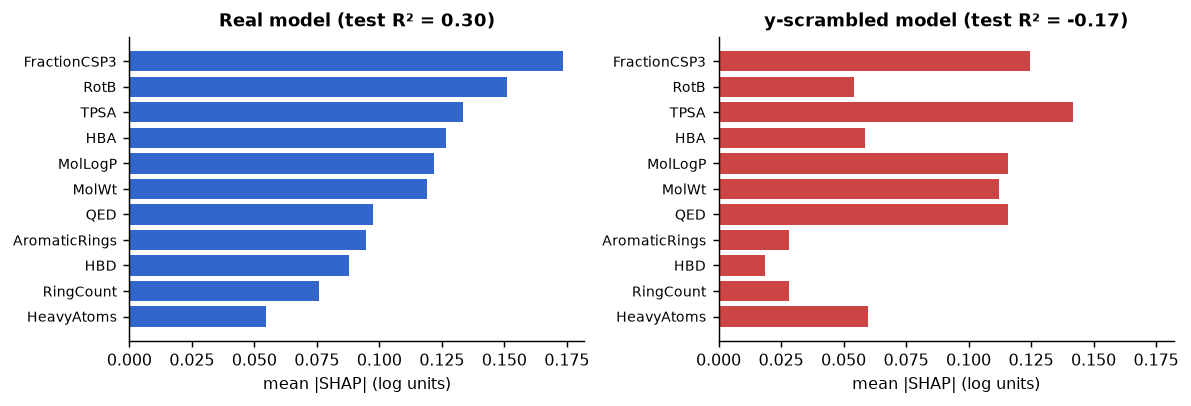

In [19]:
# Figure 7: the scrambled model's explanation, side by side with the real one.
fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.2), sharex=True)
o = np.argsort(np.abs(sv).mean(0))
axes[0].barh(range(11), np.abs(sv).mean(0)[o], color="#36c")
axes[0].set_yticks(range(11)); axes[0].set_yticklabels([DESC[j] for j in o], fontsize=7.5)
axes[0].set_xlabel("mean |SHAP| (log units)")
axes[0].set_title(f"Real model (test R² = {r2_score(y[ite], gbm.predict(Xd[ite])):.2f})")
axes[1].barh(range(11), np.abs(sv_scram).mean(0)[o], color="#c44")
axes[1].set_yticks(range(11)); axes[1].set_yticklabels([DESC[j] for j in o], fontsize=7.5)
axes[1].set_xlabel("mean |SHAP| (log units)")
axes[1].set_title(f"y-scrambled model (test R² = {r2_score(y[ite], gbm_scram.predict(Xd[ite])):.2f})")
fig.tight_layout()

<p class="caption"><b>Figure 7.</b> Mean absolute SHAP value per descriptor for the real model (blue) and for a model of identical architecture trained on permuted labels (red), on the same feature ordering. The scrambled model has no out-of-sample predictive power, yet it distributes about seven tenths of the real model's total attribution mass across the descriptors — and its three top-ranked descriptors (polar surface area, fraction of sp3 carbon and drug-likeness) are exactly the kind a reader would nod at.</p>

This is the single most useful figure to put in a supplementary section. The scrambled model's explanation is not noise-shaped; it is *story*-shaped, because SHAP faithfully reports what the model does, and what the model does is read the structure it over-fitted. An interpretation section that would survive this control states (i) the model's held-out performance, (ii) that the explanation was computed on held-out data, and (iii) ideally, the scrambled comparison.

**Control 2: stability across folds.** If the explanation is a property of the data and not of one particular fit, refitting on different subsets should preserve it.

In [20]:
# Control 2: mean |SHAP| rankings across five cross-validation folds.
from sklearn.model_selection import KFold
fold_imp = []
for tr, te in KFold(5, shuffle=True, random_state=0).split(Xd):
    g = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.05, random_state=0, verbose=-1).fit(Xd[tr], y[tr])
    fold_imp.append(np.abs(shap.TreeExplainer(g).shap_values(Xd[te])).mean(0))
FI = np.array(fold_imp)
pairs = [spearmanr(FI[i], FI[j]).statistic for i in range(5) for j in range(i + 1, 5)]
print("mean |SHAP| per fold (rows = folds):")
print(pd.DataFrame(FI, columns=DESC, index=[f"fold {k+1}" for k in range(5)]).round(3).to_string())
print(f"\npairwise Spearman correlations between folds: min {min(pairs):.3f}, "
      f"median {np.median(pairs):.3f}, max {max(pairs):.3f}")
top1 = [DESC[int(np.argmax(f))] for f in FI]
print(f"top feature per fold: {top1}")

mean |SHAP| per fold (rows = folds):
        MolWt  MolLogP   TPSA    HBD    HBA   RotB  AromaticRings  RingCount  HeavyAtoms  FractionCSP3    QED
fold 1  0.093    0.110  0.129  0.073  0.123  0.137          0.094      0.075       0.052         0.165  0.098
fold 2  0.118    0.095  0.126  0.074  0.133  0.131          0.097      0.076       0.065         0.172  0.085
fold 3  0.121    0.109  0.131  0.065  0.129  0.171          0.098      0.060       0.049         0.180  0.078
fold 4  0.118    0.101  0.134  0.075  0.135  0.171          0.085      0.065       0.048         0.185  0.085
fold 5  0.125    0.117  0.144  0.095  0.144  0.146          0.097      0.051       0.070         0.165  0.082

pairwise Spearman correlations between folds: min 0.864, median 0.945, max 0.982
top feature per fold: ['FractionCSP3', 'FractionCSP3', 'FractionCSP3', 'FractionCSP3', 'FractionCSP3']


The fold-to-fold rank correlations are high and the top feature is the same in every fold, so for *this* model and *this* data set the global explanation is stable. Note what that does and does not license: it licenses the sentence "the ranking is reproducible under resampling"; it does not license "fraction of sp3 carbon drives ROCK1 potency", because Control 1 showed that a model with no predictive power produces a comparably confident ranking.

**Control 3: the Rashomon effect.** Several models can fit the same data almost equally well and explain it differently — Breiman's "multiplicity of good models"<sup class="c"><a href="#r20">[20]</a></sup>, now studied as the Rashomon set<sup class="c"><a href="#r19">[19]</a></sup>. The practical test is to fit a few defensible alternatives and compare both their accuracy and their explanations. Here the three tree ensembles land within about 0.05 R² of one another while the linear model is far behind, so the Rashomon comparison is between the three ensembles.

In [21]:
# Control 3: four defensible models, their accuracy, and their top-3 features.
from sklearn.ensemble import ExtraTreesRegressor
models = {
    "ridge (linear)": (ridge, Zd),
    "gradient boosting": (gbm, Xd),
    "random forest": (RandomForestRegressor(300, min_samples_leaf=2, random_state=0).fit(Xd[itr], y[itr]), Xd),
    "extra trees": (ExtraTreesRegressor(300, min_samples_leaf=2, random_state=0).fit(Xd[itr], y[itr]), Xd),
}
rash = []
for name, (m, XX) in models.items():
    r2 = r2_score(y[ite], m.predict(XX[ite]))
    p = permutation_importance(m, XX[ite], y[ite], n_repeats=10, random_state=0, scoring="r2")
    top3 = [DESC[j] for j in np.argsort(-p.importances_mean)[:3]]
    rash.append({"model": name, "test R2": r2, "top 3 by permutation importance": ", ".join(top3)})
    globals()[f"_imp_{name[:4]}"] = p.importances_mean
rash = pd.DataFrame(rash)
print(rash.round(3).to_string(index=False))
r2span = rash["test R2"].max() - rash["test R2"].min()
print(f"\nspread in test R2 across the four models: {r2span:.3f}")
imps = np.array([globals()[f"_imp_{n[:4]}"] for n in models])
pr = [spearmanr(imps[i], imps[j]).statistic for i in range(4) for j in range(i + 1, 4)]
print(f"pairwise Spearman between their importance profiles: min {min(pr):.3f}, median {np.median(pr):.3f}")

            model  test R2   top 3 by permutation importance
   ridge (linear)    0.093                    RotB, QED, HBA
gradient boosting    0.296           FractionCSP3, RotB, HBA
    random forest    0.339 RotB, FractionCSP3, AromaticRings
      extra trees    0.350          RotB, AromaticRings, HBA

spread in test R2 across the four models: 0.257
pairwise Spearman between their importance profiles: min 0.345, median 0.577


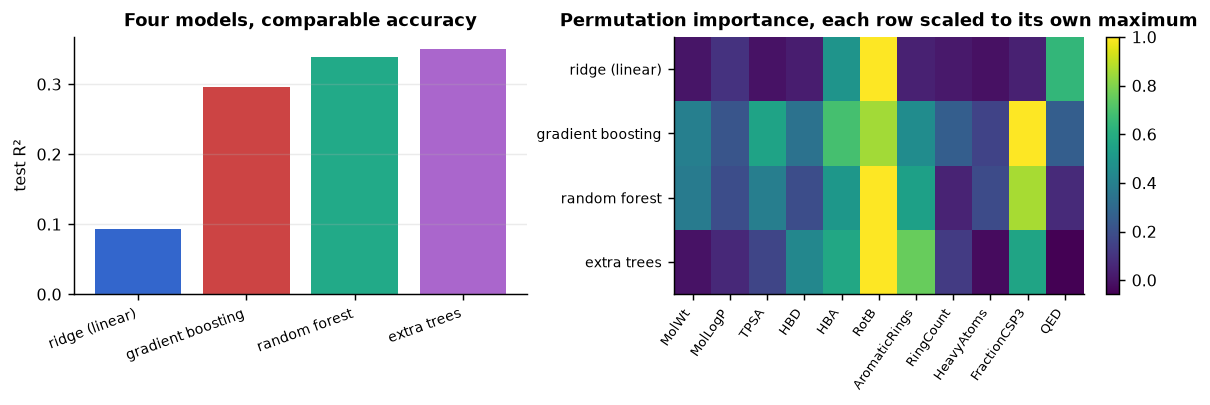

In [22]:
# Figure 8: the Rashomon picture - similar accuracy, different explanations.
fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.2))
axes[0].bar(range(len(rash)), rash["test R2"], color=["#36c", "#c44", "#2a8", "#a6c"])
axes[0].set_xticks(range(len(rash))); axes[0].set_xticklabels(rash["model"], rotation=20, ha="right", fontsize=7.5)
axes[0].set_ylabel("test R²"); axes[0].set_title("Four models, comparable accuracy")
axes[0].grid(alpha=.25, axis="y")
im = axes[1].imshow(imps / np.abs(imps).max(axis=1, keepdims=True), cmap="viridis", aspect="auto")
axes[1].set_yticks(range(4)); axes[1].set_yticklabels(list(models), fontsize=7.5)
axes[1].set_xticks(range(11)); axes[1].set_xticklabels(DESC, rotation=55, ha="right", fontsize=7)
axes[1].set_title("Permutation importance, each row scaled to its own maximum")
fig.colorbar(im, ax=axes[1], fraction=.046)
fig.tight_layout()

<p class="caption"><b>Figure 8.</b> Left: held-out R² of four defensible models of the same data — the three tree ensembles within about 0.05 of each other, ridge regression well below them. Right: their permutation-importance profiles, each row scaled to its own maximum. The three ensembles predict almost equally well and still disagree about the leading descriptor (gradient boosting puts fraction of sp3 carbon first, both forests put rotatable bonds first), and their importance profiles correlate only moderately — the Rashomon effect in one picture.</p>

## 11. Explanations are not causal claims

Every method in this unit answers the same question: *how does the fitted function respond when I change its inputs?* None of them answers *what happens in a cell when a chemist changes a molecule*. Three gaps separate them.

**Confounding.** The training table is an accumulation of published series. If one laboratory's potent series happens to be lipophilic, the model will attribute potency to lipophilicity and the explanation will faithfully report that attribution. The association is real in the data and may be an artefact of publication history.

**Manipulability.** "Reduce TPSA by 20 Å²" is not an intervention a chemist can perform without changing twelve other descriptors at the same time; in the data those descriptors move together. An explanation that varies one descriptor at a time describes a world in which they are separable.

**The noise floor.** Public IC50 and Ki values carry an experimental uncertainty of roughly 0.4–0.5 log units between laboratories<sup class="c"><a href="#r35">[35]</a></sup>. Attributions smaller than that are inside the measurement error of the target they are explaining — a decisive reason to report attributions with a scale, not as a bare ranking. <a href="../U17_Uncertainty_AD/index.html">Unit 17</a> makes this floor quantitative.

Rudin's conclusion<sup class="c"><a href="#r1">[1]</a></sup> follows from the three: for a decision that matters, prefer a model you can read to a black box with an explanation — and measure the cost of readability instead of assuming it. On this table the cost is large (ridge loses about two thirds of the boosted model's R²), so the ensemble is defensible; on many tabular problems it is not, and the comparison is one line of code. Either way the burden of proof belongs with the black box, and the controls of Section 10 are how it is discharged<sup class="c"><a href="#r18">[18]</a></sup>.

### How to write the interpretation paragraph

1. State the model and its held-out performance before any explanation.
2. Say which explanation method, on which data split, with which background distribution, and give the magnitudes with units.
3. Distinguish global from local statements explicitly.
4. Report at least one control (scrambled labels, fold stability, or an alternative model class) and the agreement between two methods.
5. Write "the model used X" or "X is associated with Y in these data", never "X causes Y", unless you ran an experiment.

In [23]:
# A compact summary of every explanation computed in this notebook, with its known failure mode.
summary = pd.DataFrame([
    ("impurity importance", "global", "free with the model",
     f"continuous noise ranked {rank_cont}/{len(NAMES)}", "biased to high-cardinality features"),
    ("permutation importance", "global", "any model, held-out data",
     f"top: {DESC[int(np.argmax(pi.importances_mean))]}", "masking + off-manifold inputs"),
    ("grouped permutation", "global", "correlated feature blocks",
     f"size group {grouped_permutation(gbm, Xd[ite], y[ite], G)['size group (MolWt, HeavyAtoms, RingCount, RotB)'][0]:+.3f} R²",
     "needs a grouping decided in advance"),
    ("PDP / ICE", "global + per-instance", "shape of an effect",
     f"{DESC[JF]} spans {np.ptp(pd_res['average'][0]):.2f} log units", "extrapolates with correlated features"),
    ("ALE", "global", "shape, on-manifold",
     f"{DESC[JF]} spans {np.ptp(ale):.2f} log units", "bin choice; first order only"),
    ("SHAP (TreeSHAP)", "local, aggregable", "additive attribution",
     f"verified against exact enumeration to {np.abs(phi_exact - phi_tree).max():.0e}", "interventional vs conditional ambiguity"),
    ("LIME", "local", "any model, sparse story",
     f"local R² {r2_0:.2f}; seed-to-seed rho {spearmanr(co0, co1).statistic:.2f}", "sampling variance; manipulable"),
    ("counterfactual", "local", "actionable statement",
     f"cheapest change {cf.iloc[0]['change in SD units']:.2f} SD of {cf.iloc[0]['descriptor']}", "may describe an impossible molecule"),
    ("atom attribution", "local, chemical", "substructure story",
     f"N in top-5 atoms for {int(attr['N among top 5'].sum())}/{len(attr)} compounds", "reflects training-set frequency too"),
], columns=["method", "scope", "what it is for", "result here", "principal failure mode"])
summary

,method,scope,what it is for,result here,principal failure mode
0,impurity importance,global,free with the model,continuous noise ranked 2/13,biased to high-cardinality features
1,permutation importance,global,"any model, held-out data",top: FractionCSP3,masking + off-manifold inputs
2,grouped permutation,global,correlated feature blocks,size group +0.248 R²,needs a grouping decided in advance
3,PDP / ICE,global + per-instance,shape of an effect,FractionCSP3 spans 0.81 log units,extrapolates with correlated features
4,ALE,global,"shape, on-manifold",FractionCSP3 spans 0.83 log units,bin choice; first order only
5,SHAP (TreeSHAP),"local, aggregable",additive attribution,verified against exact enumeration to 1e-07,interventional vs conditional ambiguity
6,LIME,local,"any model, sparse story",local R² 0.30; seed-to-seed rho 0.89,sampling variance; manipulable
7,counterfactual,local,actionable statement,cheapest change 1.53 SD of RotB,may describe an impossible molecule
8,atom attribution,"local, chemical",substructure story,N in top-5 atoms for 5/6 compounds,reflects training-set frequency too


<p class="caption"><b>Table 1.</b> The nine explanations computed in this notebook, with the number each produced and the failure mode that must be stated alongside it.</p>

## 12. Summary

Explanations are produced on demand and always look like knowledge, so they need the same discipline as predictions.

**Intrinsic first.** A linear model, a shallow tree or an additive model is its own explanation, exactly and permanently; everything else is a reconstruction. On these eleven descriptors the interpretable model is clearly worse (test R² about 0.09 against 0.30 for gradient boosting), so the black box is justified here — but that is a measurement, not an assumption, and it is the measurement Rudin asks for<sup class="c"><a href="#r1">[1]</a></sup> before any post-hoc explanation is accepted.

**Global importances.** Impurity importance is biased towards features with many split points and ranked a column of random numbers in mid-table; never publish it. Permutation importance, measured on held-out data, is the model-agnostic replacement, but correlated features mask each other and the permutation itself creates impossible inputs<sup class="c"><a href="#r5">[5]</a></sup>; permuting correlated descriptors as a group recovered several times the importance that either column showed alone.

**Shapes.** PDP averages over feature combinations that may not exist, ICE shows whether the average means anything, ALE restricts the computation to intervals where data lives. For correlated descriptors, report ALE.

**Attributions.** Shapley values are the unique attribution satisfying efficiency, symmetry, dummy and additivity<sup class="c"><a href="#r9">[9]</a><a href="#r10">[10]</a></sup>, and TreeSHAP<sup class="c"><a href="#r11">[11]</a></sup> computes them exactly for tree ensembles — verified here against brute-force enumeration on a four-feature model. LIME gives a local linear story whose coefficients moved between random seeds and whose local fit was modest; always report both.

**Domain mapping.** Morgan bits map back to atoms, so a fingerprint model can be made to colour molecules; the attribution put nitrogen and aromatic atoms on the hinge-binding heterocycles of known ROCK inhibitors, consistent with the published pharmacophore<sup class="c"><a href="#r30">[30]</a></sup> — and equally consistent with the training set's substructure frequencies.

**Controls.** A y-scrambled model with negative held-out R² produced a comparably confident, chemically plausible SHAP ranking: plausibility is not evidence. Fold-to-fold rank correlations were high, which establishes reproducibility and nothing more. Four models with nearly equal accuracy disagreed about which descriptors matter.

**Causality.** Every explanation here is a statement about the fitted function. Confounding by publication history, the impossibility of varying one descriptor alone, and an experimental noise floor of about half a log unit<sup class="c"><a href="#r35">[35]</a></sup> each separate "the model used X" from "X causes potency". <a href="../U17_Uncertainty_AD/index.html">Unit 17</a> takes the next step and asks whether a given prediction should be made at all; <a href="../U19_Virtual_Screening/index.html">Unit 19</a> applies the same scepticism to screening scores, and <a href="../U23_Communication/index.html">Unit 23</a> to the figures that carry these claims into a manuscript.

## 13. Self-assessment

<details><summary>1. Why is impurity importance biased, and in which direction?</summary>
<p>Because it accumulates the criterion reduction achieved by whichever splits the tree happened to choose, and a feature with many candidate thresholds (continuous or high-cardinality) has more chances to fit the training residuals than a binary one. The bias favours continuous and many-valued features: in Section 3 a column of standard normal noise ranked in mid-table while a random binary column ranked last.</p></details>

<details><summary>2. Two descriptors correlate at 0.98 and both show near-zero permutation importance. What do you conclude?</summary>
<p>Nothing about their relevance. Destroying one leaves the model able to read the other, so each appears dispensable — masking. Permute them together: in Section 4 the pair cost more R² than the sum of the individual drops, and the four-descriptor size group cost several times more.</p></details>

<details><summary>3. When is a partial-dependence plot misleading, and what replaces it?</summary>
<p>When the feature is correlated with others, because the PDP evaluates the model at combinations that do not occur (a molecule with the weight of a peptide and the heavy-atom count of benzene). ALE replaces it: it accumulates average prediction differences computed only inside intervals where data exists. Also plot ICE curves to see whether the average hides opposing individual effects.</p></details>

<details><summary>4. State the four axioms that make Shapley values unique, and which one lets you draw a waterfall plot.</summary>
<p>Efficiency, symmetry, dummy and additivity. Efficiency — the attributions sum to the prediction minus the expected prediction — is what makes the waterfall add up exactly, as verified numerically in Section 6.</p></details>

<details><summary>5. Why do interventional and conditional SHAP disagree, and which should you report?</summary>
<p>Interventional SHAP replaces out-of-coalition features with independent background draws, so it asks what the model does on possibly impossible inputs; conditional SHAP samples them from their distribution given the coalition, so it spreads credit across correlated features. They answer different questions: interventional is about the model's mechanism, conditional about the data's information. Report which one you used and the background set you used with it.</p></details>

<details><summary>6. Your LIME explanation changes when you change the seed. Is the method broken?</summary>
<p>No — it is sampling-based, and the variability is part of its output. Report several seeds and the local R² of the surrogate. If the ordering of the top features is unstable, the explanation does not support a claim about those features; and because the perturbations are drawn off the data manifold, they can in principle be exploited to hide a model's behaviour.</p></details>

<details><summary>7. A counterfactual says "lower TPSA by 20 Å² and the compound becomes active". What are the two objections?</summary>
<p>First, descriptor-space feasibility: no molecule may exist with that descriptor vector, and nothing checks synthetic accessibility. Second, non-manipulability: TPSA cannot be changed alone — any real modification moves several descriptors together, so the counterfactual describes a direction in feature space, not a chemical plan.</p></details>

<details><summary>8. How do you turn a 2,048-bit fingerprint explanation into something a chemist can read?</summary>
<p>Each set bit records a circular atom environment with a known central atom and radius; RDKit reports them. Distribute each bit's attribution over the atoms of its environment and highlight the atoms with the largest totals. State the fingerprint, the radius and whether attributions were summed or averaged per atom.</p></details>

<details><summary>9. A y-scrambled model's SHAP summary looks chemically sensible. What does that prove?</summary>
<p>That "the explanation looks sensible" carries no information about whether the model learned anything. The scrambled model in Section 10 had negative held-out R² and still spread a similar amount of attribution across the descriptors, with lipophilicity and drug-likeness near the top. An interpretation section must therefore lead with held-out performance.</p></details>

<details><summary>10. Fold-to-fold Spearman correlations of mean |SHAP| are above 0.9. What may you now claim?</summary>
<p>That the ranking is reproducible under resampling of this data set with this model class. Not that it is causal, not that another model class would agree (Figure 8 shows it may not), and not that the features matter biologically.</p></details>

<details><summary>11. What is the Rashomon effect and how should it change what you write?</summary>
<p>Several models can fit the data almost equally well while attributing the signal to different features: in Section 10 the three tree ensembles were within about 0.05 R² and still disagreed about the leading descriptor, with importance profiles correlating only moderately. It implies that "the important features are A, B, C" is a statement about one fitted model, not about the problem; write it that way, and report at least one alternative model class.</p></details>

<details><summary>12. Why does the experimental error of public bioactivity data limit what an explanation can mean?</summary>
<p>Because the target itself is uncertain by roughly half a log unit between laboratories, any attribution smaller than that is inside the noise of what is being explained. Report attributions with units and compare them with the measurement error before interpreting a ranking position.</p></details>

## Glossary

<dl class="gloss">
<dt>ALE (accumulated local effects)</dt><dd>Effect curve built by accumulating average prediction differences across bin edges, using only data inside each bin; unbiased under correlated features.</dd>
<dt>Counterfactual explanation</dt><dd>The smallest change to an instance's features that flips the model's decision.</dd>
<dt>Global vs local explanation</dt><dd>A statement about the model's average behaviour over a population versus about one individual prediction.</dd>
<dt>ICE (individual conditional expectation)</dt><dd>One partial-dependence curve per observation, plotted without averaging.</dd>
<dt>Impurity importance</dt><dd>Total reduction in the splitting criterion attributed to a feature in a tree ensemble; biased towards features with many split points.</dd>
<dt>Interventional vs conditional value function</dt><dd>In Shapley estimation, replacing absent features by independent background draws versus by draws from their conditional distribution.</dd>
<dt>Intrinsically interpretable model</dt><dd>A model whose structure is itself the explanation: linear model, shallow tree, rule list, generalised additive model.</dd>
<dt>LIME</dt><dd>Local surrogate: a sparse linear model fitted to the black box's predictions on perturbations around one instance, weighted by proximity.</dd>
<dt>Masking</dt><dd>Mutual suppression of permutation importance between correlated features, each covering for the other.</dd>
<dt>Partial dependence (PDP)</dt><dd>Average prediction when one feature is set to a value for every observation and the others are left unchanged.</dd>
<dt>Permutation importance</dt><dd>Drop in a held-out performance metric when one feature's values are shuffled.</dd>
<dt>Rashomon effect</dt><dd>The existence of several models with nearly equal accuracy and materially different explanations.</dd>
<dt>Shapley value</dt><dd>Average marginal contribution of a feature over all coalitions; the unique attribution satisfying efficiency, symmetry, dummy and additivity.</dd>
<dt>SHAP / TreeSHAP</dt><dd>Shapley-value framework for model explanation, and its exact polynomial-time algorithm for tree ensembles.</dd>
<dt>Similarity map / atom colouring</dt><dd>Visualisation that distributes a model's fingerprint-bit attributions over the atoms of the corresponding circular environments.</dd>
<dt>y-scrambling</dt><dd>Refitting the identical pipeline on permuted labels as a negative control, for performance and for explanations alike.</dd>
</dl>

## References and further reading

<ol class="refs">
<li id="r1">Rudin C. Stop explaining black box machine learning models for high stakes decisions and use interpretable models instead. <em>Nat Mach Intell</em>. 2019;1(5):206-215. <a href="https://doi.org/10.1038/s42256-019-0048-x">doi:10.1038/s42256-019-0048-x</a></li>
<li id="r2">Lipton ZC. The mythos of model interpretability. <em>Commun ACM</em>. 2018;61(10):36-43. <a href="https://doi.org/10.1145/3233231">doi:10.1145/3233231</a></li>
<li id="r3">Breiman L. Random forests. <em>Mach Learn</em>. 2001;45:5-32. <a href="https://doi.org/10.1023/A:1010933404324">doi:10.1023/A:1010933404324</a></li>
<li id="r4">Strobl C, Boulesteix AL, Zeileis A, Hothorn T. Bias in random forest variable importance measures: illustrations, sources and a solution. <em>BMC Bioinformatics</em>. 2007;8:25. <a href="https://doi.org/10.1186/1471-2105-8-25">doi:10.1186/1471-2105-8-25</a></li>
<li id="r5">Hooker G, Mentch L, Zhou S. Unrestricted permutation forces extrapolation: variable importance requires at least one more model, or there is no free variable importance. <em>Stat Comput</em>. 2021;31:82. <a href="https://doi.org/10.1007/s11222-021-10057-z">doi:10.1007/s11222-021-10057-z</a></li>
<li id="r6">Friedman JH. Greedy function approximation: a gradient boosting machine. <em>Ann Stat</em>. 2001;29(5):1189-1232. <a href="https://doi.org/10.1214/aos/1013203451">doi:10.1214/aos/1013203451</a></li>
<li id="r7">Goldstein A, Kapelner A, Bleich J, Pitkin E. Peeking inside the black box: visualizing statistical learning with plots of individual conditional expectation. <em>J Comput Graph Stat</em>. 2015;24(1):44-65. <a href="https://doi.org/10.1080/10618600.2014.907095">doi:10.1080/10618600.2014.907095</a></li>
<li id="r8">Apley DW, Zhu J. Visualizing the effects of predictor variables in black box supervised learning models. <em>J R Stat Soc Series B</em>. 2020;82(4):1059-1086. <a href="https://doi.org/10.1111/rssb.12377">doi:10.1111/rssb.12377</a></li>
<li id="r9">Shapley LS. A value for n-person games. In: Kuhn HW, Tucker AW, eds. <em>Contributions to the Theory of Games II</em>. Princeton University Press; 1953:307-317. <a href="https://doi.org/10.1515/9781400881970-018">doi:10.1515/9781400881970-018</a></li>
<li id="r10">Lundberg SM, Lee SI. A unified approach to interpreting model predictions. In: <em>NeurIPS 30</em>; 2017. <a href="https://doi.org/10.48550/arXiv.1705.07874">doi:10.48550/arXiv.1705.07874</a></li>
<li id="r11">Lundberg SM, Erion G, Chen H, et al. From local explanations to global understanding with explainable AI for trees. <em>Nat Mach Intell</em>. 2020;2(1):56-67. <a href="https://doi.org/10.1038/s42256-019-0138-9">doi:10.1038/s42256-019-0138-9</a></li>
<li id="r12">Strumbelj E, Kononenko I. Explaining prediction models and individual predictions with feature contributions. <em>Knowl Inf Syst</em>. 2014;41:647-665. <a href="https://doi.org/10.1007/s10115-013-0679-x">doi:10.1007/s10115-013-0679-x</a></li>
<li id="r13">Aas K, Jullum M, Loland A. Explaining individual predictions when features are dependent: more accurate approximations to Shapley values. <em>Artif Intell</em>. 2021;298:103502. <a href="https://doi.org/10.1016/j.artint.2021.103502">doi:10.1016/j.artint.2021.103502</a></li>
<li id="r14">Ribeiro MT, Singh S, Guestrin C. "Why should I trust you?": explaining the predictions of any classifier. In: <em>Proc. 22nd ACM SIGKDD</em>; 2016:1135-1144. <a href="https://doi.org/10.1145/2939672.2939778">doi:10.1145/2939672.2939778</a></li>
<li id="r15">Slack D, Hilgard S, Jia E, Singh S, Lakkaraju H. Fooling LIME and SHAP: adversarial attacks on post hoc explanation methods. In: <em>AAAI/ACM Conf. on AI, Ethics, and Society</em>; 2020:180-186. <a href="https://doi.org/10.1145/3375627.3375830">doi:10.1145/3375627.3375830</a></li>
<li id="r16">Mothilal RK, Sharma A, Tan C. Explaining machine learning classifiers through diverse counterfactual explanations. In: <em>Proc. 2020 Conf. on Fairness, Accountability, and Transparency</em>; 2020:607-617. <a href="https://doi.org/10.1145/3351095.3372850">doi:10.1145/3351095.3372850</a></li>
<li id="r17">Ghorbani A, Abid A, Zou J. Interpretation of neural networks is fragile. <em>Proc AAAI Conf Artif Intell</em>. 2019;33:3681-3688. <a href="https://doi.org/10.1609/aaai.v33i01.33013681">doi:10.1609/aaai.v33i01.33013681</a></li>
<li id="r18">Adebayo J, Gilmer J, Muelly M, Goodfellow I, Hardt M, Kim B. Sanity checks for saliency maps. <em>arXiv</em>. 2018:1810.03292. <a href="https://doi.org/10.48550/arXiv.1810.03292">doi:10.48550/arXiv.1810.03292</a></li>
<li id="r19">Semenova L, Rudin C, Parr R. On the existence of simpler machine learning models. In: <em>Proc. 2022 ACM Conf. on Fairness, Accountability, and Transparency</em>; 2022:1827-1858. <a href="https://doi.org/10.1145/3531146.3533232">doi:10.1145/3531146.3533232</a></li>
<li id="r20">Breiman L. Statistical modeling: the two cultures. <em>Stat Sci</em>. 2001;16(3):199-231. <a href="https://doi.org/10.1214/ss/1009213726">doi:10.1214/ss/1009213726</a></li>
<li id="r21">Rodriguez-Perez R, Bajorath J. Interpretation of compound activity predictions from complex machine learning models using local approximations and Shapley values. <em>J Med Chem</em>. 2020;63(16):8761-8777. <a href="https://doi.org/10.1021/acs.jmedchem.9b01101">doi:10.1021/acs.jmedchem.9b01101</a></li>
<li id="r22">Jimenez-Luna J, Grisoni F, Schneider G. Drug discovery with explainable artificial intelligence. <em>Nat Mach Intell</em>. 2020;2(10):573-584. <a href="https://doi.org/10.1038/s42256-020-00236-4">doi:10.1038/s42256-020-00236-4</a></li>
<li id="r23">Riniker S, Landrum GA. Similarity maps - a visualization strategy for molecular fingerprints and machine-learning methods. <em>J Cheminform</em>. 2013;5:43. <a href="https://doi.org/10.1186/1758-2946-5-43">doi:10.1186/1758-2946-5-43</a></li>
<li id="r24">Rogers D, Hahn M. Extended-connectivity fingerprints. <em>J Chem Inf Model</em>. 2010;50(5):742-754. <a href="https://doi.org/10.1021/ci100050t">doi:10.1021/ci100050t</a></li>
<li id="r25">Maggiora GM. On outliers and activity cliffs - why QSAR often disappoints. <em>J Chem Inf Model</em>. 2006;46(4):1535. <a href="https://doi.org/10.1021/ci060117s">doi:10.1021/ci060117s</a></li>
<li id="r26">Stumpfe D, Bajorath J. Exploring activity cliffs in medicinal chemistry. <em>J Med Chem</em>. 2012;55(7):2932-2942. <a href="https://doi.org/10.1021/jm201706b">doi:10.1021/jm201706b</a></li>
<li id="r27">van Tilborg D, Alenicheva A, Grisoni F. Exposing the limitations of molecular machine learning with activity cliffs. <em>J Chem Inf Model</em>. 2022;62(23):5938-5951. <a href="https://doi.org/10.1021/acs.jcim.2c01073">doi:10.1021/acs.jcim.2c01073</a></li>
<li id="r28">Rucker C, Rucker G, Meringer M. y-Randomization and its variants in QSPR/QSAR. <em>J Chem Inf Model</em>. 2007;47(6):2345-2357. <a href="https://doi.org/10.1021/ci700157b">doi:10.1021/ci700157b</a></li>
<li id="r29">Zdrazil B, Felix E, Hunter F, et al. The ChEMBL Database in 2023. <em>Nucleic Acids Res</em>. 2024;52(D1):D1180-D1192. <a href="https://doi.org/10.1093/nar/gkad1004">doi:10.1093/nar/gkad1004</a></li>
<li id="r30">Feng Y, LoGrasso PV, Defert O, Li R. Rho kinase (ROCK) inhibitors and their therapeutic potential. <em>J Med Chem</em>. 2016;59(6):2269-2300. <a href="https://doi.org/10.1021/acs.jmedchem.5b00683">doi:10.1021/acs.jmedchem.5b00683</a></li>
<li id="r31">Jimenez-Luna J, Skalic M, Weskamp N, Schneider G. Coloring molecules with explainable artificial intelligence for preclinical relevance assessment. <em>J Chem Inf Model</em>. 2021;61(3):1083-1094. <a href="https://doi.org/10.1021/acs.jcim.0c01344">doi:10.1021/acs.jcim.0c01344</a></li>
<li id="r32">Molnar C, Konig G, Herbinger J, et al. General pitfalls of model-agnostic interpretation methods for machine learning models. In: <em>xxAI - Beyond Explainable AI</em>. LNCS 13200. Springer; 2022:39-68. <a href="https://doi.org/10.1007/978-3-031-04083-2_4">doi:10.1007/978-3-031-04083-2_4</a></li>
<li id="r33">Sheridan RP. Interpretation of QSAR models by coloring atoms according to changes in predicted activity: how robust is it? <em>J Chem Inf Model</em>. 2019;59(4):1324-1337. <a href="https://doi.org/10.1021/acs.jcim.8b00825">doi:10.1021/acs.jcim.8b00825</a></li>
<li id="r34">Polishchuk P. Interpretation of quantitative structure-activity relationship models: past, present, and future. <em>J Chem Inf Model</em>. 2017;57(11):2618-2639. <a href="https://doi.org/10.1021/acs.jcim.7b00274">doi:10.1021/acs.jcim.7b00274</a></li>
<li id="r35">Kramer C, Kalliokoski T, Gedeck P, Vulpetti A. The experimental uncertainty of heterogeneous public Ki data. <em>J Med Chem</em>. 2012;55(11):5165-5173. <a href="https://doi.org/10.1021/jm300131x">doi:10.1021/jm300131x</a></li>
</ol>

<h4>Textbooks</h4>
<ul>
<li>Molnar C. <em>Interpretable Machine Learning</em>. 2nd ed.; 2022 (free online). - The reference for every method in this unit, with the same examples in more detail.</li>
<li>Hastie T, Tibshirani R, Friedman J. <em>The Elements of Statistical Learning</em>. 2nd ed. Springer; 2009. - Section 10.13 on partial dependence and relative importance.</li>
<li>Biecek P, Burzykowski T. <em>Explanatory Model Analysis</em>. Chapman &amp; Hall; 2021 (free online). - A complete workflow view of explanation, with ceteris-paribus profiles.</li>
</ul>

<h4>Online resources</h4>
<ul>
<li>scikit-learn user guide, "Inspection": permutation importance and partial dependence: <a href="https://scikit-learn.org/stable/inspection.html">scikit-learn.org/stable/inspection.html</a>.</li>
<li>SHAP documentation and API: <a href="https://shap.readthedocs.io/">shap.readthedocs.io</a>.</li>
<li>RDKit Cookbook, bit-information maps and similarity maps: <a href="https://www.rdkit.org/docs/Cookbook.html">rdkit.org/docs/Cookbook.html</a>.</li>
<li>TeachOpenCADD talktorial on interpretable machine learning for compound activity: <a href="https://projects.volkamerlab.org/teachopencadd/">projects.volkamerlab.org/teachopencadd</a>.</li>
</ul>